# BÀI TẬP CHƯƠNG 2 — CUSTOMER CHURN PRIORITY SCORING
**Học phần:** Hệ hỗ trợ quyết định (INS305)  
**Dữ liệu:** Telco-Customer-Churn.csv (7.043 khách hàng), lấy từ tài liệu thực hành Chương 3.  
**Mục tiêu:** ưu tiên *nguồn lực chăm sóc* chứ không chỉ dự đoán churn.  
**Lưu ý:** `ComplaintCount` và `RetentionCost` **được mô phỏng**, không phải số liệu khiếu nại hay chi phí thực; `CustomerValue` là proxy, không phải CLV thực tế. Có thể thay bằng dữ liệu hợp lệ khi triển khai.

## 1. Problem statement
Nhà quản lý chăm sóc khách hàng cần xác định khách hàng nào cần được liên hệ trước, cân nhắc đồng thời nguy cơ rời bỏ, giá trị khách hàng, thâm niên, số khiếu nại và chi phí giữ chân. Bộ dữ liệu chứa nhãn `Churn` quá khứ và các đặc điểm khách hàng, không chứa số khiếu nại hay chi phí retention thực tế. Mô hình xác suất churn là một chỉ dấu đầu vào của DSS, **không phải quyết định giữ chân cuối cùng**.

## 2. Decision Canvas
| Thành phần | Nội dung | Lý do / điểm cần kiểm tra |
|---|---|---|
| Decision maker | Quản lý CRM / trưởng bộ phận chăm sóc khách hàng | Phân bổ nhân sự và kinh phí |
| Objective | Ưu tiên khách hàng cần giữ chân để tập trung chăm sóc | Không chỉ tối đa hóa xác suất churn |
| Alternatives | 7.043 khách hàng, định danh bằng `customerID` | Mỗi khách hàng là một phương án |
| Criteria | ChurnRisk, CustomerValue, TenureRisk, ComplaintCount, RetentionCost | 5 tiêu chí theo ảnh đề bài |
| Weights | 0,40; 0,25; 0,15; 0,10; 0,10 | Giả định quản trị ban đầu; tổng = 1 |
| Constraints | Kịch bản hạn chế ngân sách; kiểm tra đồng ý liên hệ; số liệu giả định | Không dùng thuộc tính nhạy cảm làm đầu vào dự báo |
| Data | Telco-Churn, 7.043 dòng, 21 cột ban đầu | Complaint / Cost không sẵn có |
| Output | Score, Rank, High/Medium/Low, Call/Offer/Monitor, phân tích scenario | Mọi hành động liên hệ yêu cầu đối chiếu consent |

**Quy tắc quản trị:** ChurnRisk cao không tự động đồng nghĩa phải chi tiền giữ chân; cân nhắc giá trị và chi phí. Không được coi kết quả scoring là nguyên nhân thực sự khiến khách rời bỏ.

## 3. Data dictionary & Criteria — Weights
| Tiêu chí | Nguồn / công thức | Hướng | Trọng số | Lý do |
|---|---|---|---:|---|
| ChurnRisk | Xác suất `Churn=Yes` do mô hình ước lượng (out-of-fold) | Benefit | 0.40 | Nguy cơ cao cần được chú ý |
| CustomerValue | `MonthlyCharges` (proxy giá trị, không phải CLV) | Benefit | 0.25 | Khách hàng có doanh thu tháng cao đáng lưu tâm |
| TenureRisk | `1 - min(tenure,72)/72` | Benefit | 0.15 | Khách mới có nguy cơ cần chăm sóc sớm |
| ComplaintCount | Số khiếu nại **mô phỏng**, không có trong Telco | Benefit | 0.10 | Tín hiệu cần hỗ trợ, không suy ra nguyên nhân |
| RetentionCost | Chi phí giữ chân **mô phỏng** | Cost | 0.10 | Ưu tiên phương án ít tốn chi phí hơn |

**Không dùng** `gender`, `SeniorCitizen` làm feature mô hình dự báo nhằm hạn chế rủi ro thiên lệch; không đánh giá khách hàng chỉ qua thông tin nhân khẩu học. `Churn` là nhãn lịch sử, chỉ dùng huấn luyện/đánh giá; không trực tiếp làm điểm. Các ngưỡng phân nhóm là giả định bài tập, không phải chính sách thực tế.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report

ROOT = Path.cwd()
DATA = ROOT / 'Telco-Customer-Churn.csv'
RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)
df = pd.read_csv(DATA)
assert len(df) >= 1000 and df['customerID'].is_unique
assert {'Churn','tenure','MonthlyCharges','Contract','TechSupport','customerID'}.issubset(df.columns)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Kích thước:',df.shape, '| Churn:',df['Churn'].value_counts().to_dict())
display(df.head(3))

Kích thước: (7043, 21) | Churn: {'No': 5174, 'Yes': 1869}


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


## 4. Mô hình ước lượng rủi ro churn
Dùng Logistic Regression với tiền xử lý số / phân loại và xác suất dự báo **out-of-fold 5-fold** để tránh chấm điểm mỗi khách hàng bằng chính mô hình đã huấn luyện trên nhãn của họ. Đây là đánh giá hồi cứu nội bộ; nếu triển khai thật cần kiểm chứng theo thời gian và dữ liệu mới. Không đưa `customerID`, `Churn`, `gender`, `SeniorCitizen` vào feature. Không dùng `TotalCharges` để giảm sự chồng lặp mạnh với tenure và monthly charges.

In [2]:
feature_cols = ['tenure','MonthlyCharges','Contract','InternetService','TechSupport',
                'OnlineSecurity','PaymentMethod','PaperlessBilling','OnlineBackup']
X = df[feature_cols].copy()
y = df['Churn'].map({'No':0,'Yes':1})
num_cols = ['tenure','MonthlyCharges']
cat_cols = [x for x in feature_cols if x not in num_cols]
prep = ColumnTransformer([
    ('num',Pipeline([('imputer',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num_cols),
    ('cat',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),
                    ('encoder',OneHotEncoder(handle_unknown='ignore'))]),cat_cols)
])
model = Pipeline([('preprocess',prep),('classifier',LogisticRegression(max_iter=1000))])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
risk_prob = cross_val_predict(model,X,y,cv=cv,method='predict_proba',n_jobs=1)[:,1]
print('OOF ROC-AUC:',round(roc_auc_score(y,risk_prob),4))
print('OOF PR-AUC:',round(average_precision_score(y,risk_prob),4))
print(classification_report(y, (risk_prob>=0.5).astype(int),digits=3))

OOF ROC-AUC: 0.84
OOF PR-AUC: 0.6452
              precision    recall  f1-score   support

           0      0.839     0.897     0.867      5174
           1      0.649     0.525     0.580      1869

    accuracy                          0.799      7043
   macro avg      0.744     0.711     0.724      7043
weighted avg      0.789     0.799     0.791      7043



## 5. Chuẩn hóa & Weighted Scoring
Công thức $S_i=\sum_j w_j n_{ij}$ với $\sum_j w_j=1$. Benefit: $(x-min)/(max-min)$, cost: $(max-x)/(max-min)$. Nếu một cột không biến thiên, tạm đặt giá trị chuẩn hóa = 1 và cảnh báo.

`ComplaintCount` là biến **mô phỏng có seed=42**; `RetentionCost` là **ước lượng giả định** tính bằng đơn vị tiền quy ước. Không đánh đồng hai biến này với quan sát thực tế.

In [3]:
rng = np.random.default_rng(42)
work = pd.DataFrame({'customerID':df['customerID'],'ChurnActual':y,
                     'ChurnRisk':risk_prob,'CustomerValue':df['MonthlyCharges'].astype(float),
                     'TenureRisk':1-np.minimum(df['tenure'].astype(float),72)/72})
# Mô phỏng khiếu nại: giả định dựa trên trạng thái TechSupport (KHÔNG phải khiếu nại thực)
rate = np.where(df['TechSupport'].eq('No'),0.85,0.35)
work['ComplaintCount'] = np.clip(rng.poisson(rate),0,5)
# Chi phí retention mô phỏng: đơn vị tiền giả định, không phải giá thị trường
work['RetentionCost'] = (25 + 0.35*df['MonthlyCharges'] +
                         12*work['ComplaintCount'] + rng.uniform(0,18,len(df))).round(2)
BASE_WEIGHTS = {'ChurnRisk':.40,'CustomerValue':.25,'TenureRisk':.15,
                'ComplaintCount':.10,'RetentionCost':.10}
BENEFIT = ['ChurnRisk','CustomerValue','TenureRisk','ComplaintCount']
COST = ['RetentionCost']
assert abs(sum(BASE_WEIGHTS.values())-1)<1e-12

def normalized(data):
    z=data.copy()
    for col in BENEFIT+COST:
        a,b=z[col].min(),z[col].max()
        if b==a:
            print('Cảnh báo: tiêu chí không biến thiên:',col)
            z[col+'_norm']=1.0
        elif col in BENEFIT:
            z[col+'_norm']=(z[col]-a)/(b-a)
        else:
            z[col+'_norm']=(b-z[col])/(b-a)
    return z

def score(data, weights):
    assert set(weights)==set(BASE_WEIGHTS) and abs(sum(weights.values())-1)<1e-9
    z=data.copy()
    z['Score']=sum(z[c+'_norm']*w for c,w in weights.items())
    z=z.sort_values(['Score','customerID'],ascending=[False,True]).reset_index(drop=True)
    z['Rank']=np.arange(1,len(z)+1)
    return z

norm=normalized(work)
ranked=score(norm,BASE_WEIGHTS)
# Ngưỡng tương đối: top 20% High, tiếp 30% Medium, còn lại Low
n=len(ranked)
ranked['Priority']=np.select([ranked['Rank']<=int(np.ceil(n*.20)),
                              ranked['Rank']<=int(np.ceil(n*.50))],['High','Medium'],default='Low')
ranked['Action']=ranked['Priority'].map({'High':'Call (sau kiểm tra consent)',
                                        'Medium':'Offer (sau kiểm tra consent)',
                                        'Low':'Monitor'})
ranked['Explanation']=ranked.apply(lambda r:
  'Nguy cơ churn {:.1%}; doanh thu tháng {:.2f}; tenure-risk {:.2f}; '
  'khiếu nại mô phỏng {}; chi phí mô phỏng {:.2f}'.format(
  r.ChurnRisk,r.CustomerValue,r.TenureRisk,int(r.ComplaintCount),r.RetentionCost),axis=1)
cols=['Rank','customerID','Score','Priority','Action','ChurnRisk','CustomerValue',
      'TenureRisk','ComplaintCount','RetentionCost','Explanation']
ranked[cols].to_csv(RESULTS/'customer_priority_scoring.csv',index=False,encoding='utf-8-sig')
display(ranked[cols].head(10).round(3))
print('Phân nhóm:',ranked['Priority'].value_counts().to_dict())

,Rank,customerID,Score,Priority,Action,ChurnRisk,CustomerValue,TenureRisk,ComplaintCount,RetentionCost,Explanation
0,1,7216-EWTRS,0.851,High,Call (sau kiểm tra consent),0.811,100.80,0.986,5,133.65,Nguy cơ churn 81.1%; doanh thu tháng 100.80; t...
1,2,1400-MMYXY,0.828,High,Call (sau kiểm tra consent),0.791,105.90,0.958,2,93.20,Nguy cơ churn 79.1%; doanh thu tháng 105.90; t...
2,3,0107-YHINA,0.827,High,Call (sau kiểm tra consent),0.820,99.75,0.986,2,97.86,Nguy cơ churn 82.0%; doanh thu tháng 99.75; te...
3,4,9497-QCMMS,0.812,High,Call (sau kiểm tra consent),0.807,93.55,0.986,1,70.21,Nguy cơ churn 80.7%; doanh thu tháng 93.55; te...
4,5,6496-SLWHQ,0.811,High,Call (sau kiểm tra consent),0.777,105.00,0.958,2,101.23,Nguy cơ churn 77.7%; doanh thu tháng 105.00; t...
5,6,3988-RQIXO,0.809,High,Call (sau kiểm tra consent),0.783,91.30,0.986,3,96.00,Nguy cơ churn 78.3%; doanh thu tháng 91.30; te...
6,7,9057-SIHCH,0.808,High,Call (sau kiểm tra consent),0.795,96.60,0.958,1,71.91,Nguy cơ churn 79.5%; doanh thu tháng 96.60; te...
7,8,6023-YEBUP,0.807,High,Call (sau kiểm tra consent),0.805,100.95,0.958,0,67.93,Nguy cơ churn 80.5%; doanh thu tháng 100.95; t...
8,9,5419-JPRRN,0.805,High,Call (sau kiểm tra consent),0.801,101.45,0.986,0,73.48,Nguy cơ churn 80.1%; doanh thu tháng 101.45; t...
9,10,0754-UKWQP,0.804,High,Call (sau kiểm tra consent),0.807,95.85,0.972,0,61.42,Nguy cơ churn 80.7%; doanh thu tháng 95.85; te...


Phân nhóm: {'Low': 3521, 'Medium': 2113, 'High': 1409}


## 6. Decision rules và hạn chế vận hành
| Điều kiện | Khuyến nghị mô phỏng |
|---|---|
| High (top 20% score) | Call, **chỉ sau kiểm tra đồng ý liên hệ**, xác minh nhu cầu |
| Medium (20–50%) | Offer phù hợp, **sau kiểm tra consent** và ngân sách |
| Low (50–100%) | Monitor định kỳ; không tự động bỏ mặc |
| Thiếu consent, chi phí thực hoặc dữ liệu khiếu nại | Chặn thực thi tự động; yêu cầu kiểm tra bằng người phụ trách |

Các ngưỡng là chính sách thử nghiệm theo phân vị của tập khách hàng. Chưa có consent trong Telco nên **không được thực hiện gọi điện / gửi ưu đãi tự động** từ file đầu ra.

## 7. Scenario analysis — Budget-limited vs Service-quality-focused
- **Baseline:** 0,40 / 0,25 / 0,15 / 0,10 / 0,10.
- **Budget-limited:** tăng RetentionCost 0,25; chọn danh sách theo score/chi phí trong ngân sách mô phỏng 12.000 đơn vị tiền.
- **Service-quality-focused:** tăng trọng số ChurnRisk và ComplaintCount nhằm ưu tiên chăm sóc cho nhóm có tín hiệu cần hỗ trợ.
- Đối chiếu sự thay đổi nhóm top 100 và tỷ lệ chồng lấp; không suy luận hiệu quả giữ chân thật vì không có dữ liệu kết quả can thiệp.

In [4]:
SCENARIOS = {
 'Baseline': {'ChurnRisk':.40,'CustomerValue':.25,'TenureRisk':.15,'ComplaintCount':.10,'RetentionCost':.10},
 'Budget-limited': {'ChurnRisk':.30,'CustomerValue':.20,'TenureRisk':.10,'ComplaintCount':.15,'RetentionCost':.25},
 'Service-quality-focused': {'ChurnRisk':.45,'CustomerValue':.20,'TenureRisk':.10,'ComplaintCount':.20,'RetentionCost':.05},
 'Risk-first sensitivity': {'ChurnRisk':.55,'CustomerValue':.15,'TenureRisk':.15,'ComplaintCount':.10,'RetentionCost':.05}
}
scored={k:score(norm,v) for k,v in SCENARIOS.items()}
base_top=set(scored['Baseline'].head(100)['customerID'])
comparison=[]
for name,z in scored.items():
    top=set(z.head(100)['customerID'])
    comparison.append({'Scenario':name,'Top100_overlap_with_base':len(base_top&top),
                       'Mean_top100_churn_risk':z.head(100)['ChurnRisk'].mean(),
                       'Mean_top100_cost_simulated':z.head(100)['RetentionCost'].mean()})
scenario_df=pd.DataFrame(comparison)
display(scenario_df.round(3))
scenario_df.to_csv(RESULTS/'scenario_comparison.csv',index=False,encoding='utf-8-sig')
# Tính danh sách chọn theo tỷ lệ score / chi phí, có ràng buộc ngân sách
budget=12000.0
b=scored['Budget-limited'].copy()
b['ScorePerCost']=b['Score']/b['RetentionCost'].clip(lower=1)
b=b.sort_values('ScorePerCost',ascending=False).copy()
b['CumulativeCost']=b['RetentionCost'].cumsum()
selected=b.loc[b['CumulativeCost']<=budget].copy()
selected.to_csv(RESULTS/'budget_selected_customers.csv',index=False,encoding='utf-8-sig')
print('Ngân sách mô phỏng:',budget,'| chọn:',len(selected),
      '| chi phí giả định:',round(selected['RetentionCost'].sum(),2))
print('Lưu ý: thuật toán greedy score/cost mang tính minh họa, không bảo đảm tối ưu 0–1 knapsack.')

,Scenario,Top100_overlap_with_base,Mean_top100_churn_risk,Mean_top100_cost_simulated
0,Baseline,100,0.775,77.951
1,Budget-limited,74,0.771,72.548
2,Service-quality-focused,60,0.757,88.941
3,Risk-first sensitivity,84,0.775,81.656


Ngân sách mô phỏng: 12000.0 | chọn: 255 | chi phí giả định: 11993.49
Lưu ý: thuật toán greedy score/cost mang tính minh họa, không bảo đảm tối ưu 0–1 knapsack.


## 8. Sensitivity analysis — biến thiên trọng số ChurnRisk
Cho ChurnRisk từ 0,20 đến 0,60, chia phần trọng số còn lại theo tỷ lệ của baseline. Quan sát mức ổn định top 100 so với baseline và vẽ biểu đồ.

,ChurnRiskWeight,Top100Overlap,MeanTop100Risk
0,0.20,75,0.754592
1,0.25,82,0.761959
2,0.30,88,0.766696
3,0.35,95,0.771976
4,0.40,100,0.774861
5,0.45,97,0.776515
6,0.50,93,0.778019
7,0.55,91,0.778693
8,0.60,90,0.779246


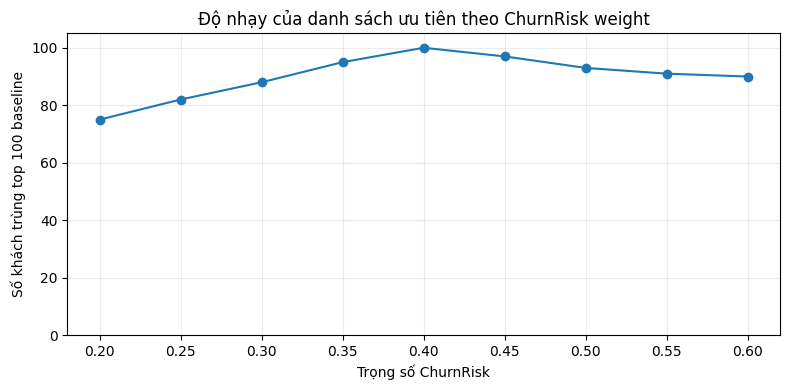

In [5]:
sensitivity=[]
other={k:v for k,v in BASE_WEIGHTS.items() if k!='ChurnRisk'}
for w in np.arange(.20,.601,.05):
    weights={'ChurnRisk':float(w)}
    weights.update({k:float((1-w)*v/sum(other.values())) for k,v in other.items()})
    ranked_temp=score(norm,weights)
    top=set(ranked_temp.head(100)['customerID'])
    sensitivity.append({'ChurnRiskWeight':round(w,2),'Top100Overlap':len(top&base_top),
                        'MeanTop100Risk':ranked_temp.head(100)['ChurnRisk'].mean()})
sens=pd.DataFrame(sensitivity)
display(sens)
sens.to_csv(RESULTS/'weight_sensitivity.csv',index=False,encoding='utf-8-sig')
plt.figure(figsize=(8,4))
plt.plot(sens['ChurnRiskWeight'],sens['Top100Overlap'],marker='o')
plt.xlabel('Trọng số ChurnRisk');plt.ylabel('Số khách trùng top 100 baseline')
plt.title('Độ nhạy của danh sách ưu tiên theo ChurnRisk weight')
plt.ylim(0,105);plt.grid(alpha=.25);plt.tight_layout()
plt.savefig(RESULTS/'sensitivity.png',dpi=160)
plt.show()

## 9. Khuyến nghị DSS & giới hạn
1. **Danh sách gốc:** ưu tiên nhóm High để nhân viên chăm sóc kiểm tra hồ sơ, xác minh consent và chọn phương thức hỗ trợ; không coi score là quyết định tự động.
2. **Khi ngân sách hạn chế:** cân nhắc danh sách `budget_selected_customers.csv` theo điểm/chi phí *mô phỏng*. Phải thay chi phí mô phỏng bằng chi phí thực và thử tối ưu ngân sách trước triển khai.
3. **Khi đặt chất lượng dịch vụ lên trước:** dùng kịch bản Service-quality-focused để tăng chú ý đến rủi ro và tín hiệu khiếu nại; **chỉ** có ý nghĩa kiểm thử trong bài tập do complaint là biến mô phỏng.
4. **Độ nhạy:** đọc `scenario_comparison.csv` và `weight_sensitivity.csv` để xem danh sách top 100 có thay đổi khi trọng số đổi hay không. Nếu thay đổi mạnh, cần thống nhất trọng số với quản lý trước khi hành động.
5. **Giới hạn:** Không có dữ liệu consent, khiếu nại thực, retention cost thực, hiệu quả ưu đãi hoặc lifetime value thật. ChurnProb là ước lượng hồi cứu, không chứng minh tác động can thiệp; cần thẩm định bias, độ lệch dữ liệu, và đánh giá sau triển khai.

## 10. AI Prompt log
**Prompt minh họa đã sử dụng để xây dựng khung:** “Dựa trên đề Customer Churn Priority Scoring, đề xuất Decision Canvas, 5 criteria với weights 0.40/0.25/0.15/0.10/0.10, Python weighted scoring, hai kịch bản ngân sách hạn chế và chất lượng dịch vụ, sensitivity, khuyến nghị và cảnh báo dữ liệu thiếu.”

**Phần đã kiểm chứng bằng code:** số hàng dữ liệu, tên cột, tổng trọng số, nhãn churn, điểm rủi ro out-of-fold, khoảng điểm chuẩn hóa, phân nhóm, và kết quả kịch bản. **Phần thay đổi/giới hạn:** không bịa complaint và retention cost là dữ liệu thật; thay bằng mô phỏng có seed; thay CustomerValue bằng proxy từ MonthlyCharges; giới hạn sử dụng các hành động call/offer.